# Politique aléatoire sur CartPole

**Projet :** Eagle-1 - pilote automatique d'atterrissage lunaire (AstroDynamics)  
**Étape :** Exercice 1 - Découvrez les blocs de construction de l'apprentissage par renforcement  
**Auteur :** Kilian Lefevre

---

## Objectif du notebook

Avant d'entraîner un agent, ce notebook fait la découverte du cycle observation → action → récompense sur l'environnement `CartPole-v1` de Gymnasium. Il répond aux questions suivantes :

- Que perçoit l'agent (espace d'observation) et que peut-il faire (espace d'actions) ?
- Quelle récompense totale obtient une politique aléatoire sur 10 épisodes ?

Cette étape n'entraîne aucun modèle : la politique choisit ses actions au hasard et sert de point de comparaison pour la suite.

In [1]:
import gymnasium as gym
import matplotlib.pyplot as plt
import pandas as pd

from rl_pilot.config import SEED

print(f"gymnasium {gym.__version__}")

gymnasium 1.4.0


## 1. Observation de l'environnement

### 1.1 Création de l'environnement

`gym.make("CartPole-v1")` crée l'environnement : un bâton est posé en équilibre sur un chariot, et l'agent doit le maintenir debout en poussant le chariot vers la gauche ou vers la droite.

Avec `render_mode="rgb_array"`, `env.render()` renvoie l'image courante sous la forme d'un tableau NumPy, que matplotlib affiche directement dans le notebook (sans ouvrir de fenêtre). Un `env.reset()` est nécessaire avant le premier rendu : il place l'environnement dans son état initial.

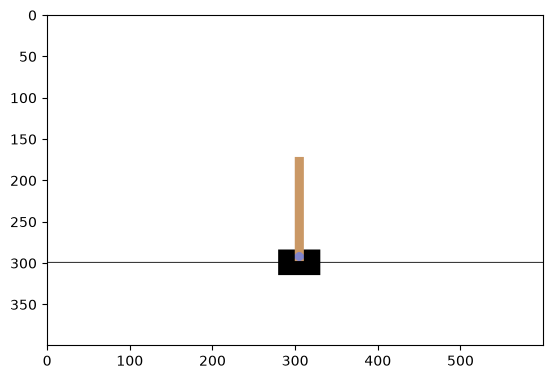

In [2]:
env = gym.make("CartPole-v1", render_mode="rgb_array")

env.reset()
plt.imshow(env.render())  # type: ignore

### 1.2 L'espace d'observation : ce que l'agent perçoit

À chaque pas, l'agent ne reçoit pas l'image du jeu mais un vecteur de **4 nombres** qui décrit complètement l'état du système. D'après la documentation de Gymnasium :

| N° | Mesure | Min | Max | Unité |
|:-:|---|--:|--:|:-:|
| 0 | Position du chariot (*Cart Position*) | -4,8 | 4,8 | m |
| 1 | Vitesse du chariot (*Cart Velocity*) | -∞ | +∞ | m/s |
| 2 | Angle du bâton (*Pole Angle*) | -0,418 (≈ -24°) | +0,418 (≈ +24°) | rad |
| 3 | Vitesse angulaire du bâton (*Pole Angular Velocity*) | -∞ | +∞ | rad/s |

L'angle vaut `0` quand le bâton est vertical. Les unités sont déduites des constantes physiques du code (gravité de 9,8, pas de temps de 0,02 s) et non de la documentation.

**Valeurs permises ≠ valeurs atteignables.** Les bornes ci-dessus sont celles que l'espace *autorise*, pas celles que l'on rencontre pendant un épisode, qui s'arrête bien avant :

| | Permis par l'espace | Fin de l'épisode (`terminated`) |
|---|:-:|:-:|
| Position du chariot | ±4,8 | ±2,4 |
| Angle du bâton | ±24° (±0,418 rad) | ±12° (±0,2095 rad) |

**État initial.** Au `reset`, les 4 valeurs sont tirées uniformément dans `(-0.05, 0.05)` : le chariot est près du centre et presque à l'arrêt, le bâton presque vertical. L'agent doit ensuite corriger un déséquilibre qui s'amplifie de lui-même.

Vérifions ces bornes avec `env.observation_space` :

In [3]:
space = env.observation_space
names = [
    "Cart Position",
    "Cart Velocity",
    "Pole Angle",
    "Pole Angular Velocity",
]

print(f"{type(space).__name__}{space.shape} - dtype : {space.dtype}")

pd.DataFrame(
    {"min": space.low, "max": space.high, "exemple": space.sample()},
    index=pd.Index(names, name="mesure"),
)

Box(4,) - dtype : float32


,min,max,exemple
mesure,,,
Cart Position,-4.800000,4.800000,-1.206313
Cart Velocity,-inf,inf,0.083630
Pole Angle,-0.418879,0.418879,-0.188773
Pole Angular Velocity,-inf,inf,0.434835


`observation_space` est un `Box` : un espace continu. Chaque mesure est un nombre réel (`float32`), il existe donc une infinité d'observations possibles. La sortie se lit ainsi :

- `Box(4,)` : un tableau de 4 valeurs, de forme `(4,)` ;
- `min` / `max` : les bornes du tableau ci-dessus, `-inf` et `inf` pour les deux vitesses, qui ne sont **pas bornées** ;
- `exemple` : un tirage de `sample()`.

**À noter :** `sample()` tire au hasard dans les bornes, ce n'est **pas un état atteignable**. Le tirage peut contenir une position au-delà de ±2,4 ou un angle au-delà de ±12°, c'est-à-dire un épisode déjà terminé, et il change à chaque exécution. Il sert uniquement à voir la forme et le type d'une observation.

### 1.3 L'espace d'actions : ce que l'agent peut faire

À chaque pas, l'agent choisit une action parmi **deux** :

| Action | Signification |
|:-:|---|
| `0` | Pousser le chariot vers la gauche (*Push cart to the left*) |
| `1` | Pousser le chariot vers la droite (*Push cart to the right*) |

Ce que cela implique :

- **Une direction, pas une intensité.** La poussée a toujours la même force (`force_mag = 10` dans le code). Il n'existe pas d'action « ne rien faire » : à chaque pas, l'agent pousse d'un côté ou de l'autre.
- **Un effet qui dépend de la situation.** D'après la documentation, la variation de vitesse dépend de l'angle du bâton : la même action n'a pas le même effet selon l'inclinaison.
- **Un pas = 0,02 s de simulation** (`tau = 0.02`) : 50 pas font une seconde, et la limite de 500 pas correspond à 10 secondes d'équilibre.

Vérifions avec `env.action_space` :

In [4]:
space = env.action_space
meanings = {0: "Pousser vers la gauche", 1: "Pousser vers la droite"}

print(f"{space} : {space.n} actions possibles")
print(f"Exemple (sample) : {space.sample()}")

pd.Series(meanings, name="signification").rename_axis("action").to_frame()

Discrete(2) : 2 actions possibles
Exemple (sample) : 0


,signification
action,
0,Pousser vers la gauche
1,Pousser vers la droite


`action_space` est un `Discrete(2)` : un espace **discret** de 2 actions entières, `0` et `1`. Contrairement à l'observation, `sample()` donne ici une action valide : c'est exactement ce que fera la politique aléatoire de la partie 2.

Cette différence de nature compte pour la suite : avec des actions discrètes, un réseau de neurones peut avoir **une sortie par action** (DQN, exercice 3).

### 1.4 Synthèse

Ok donc comme attendu l'espace des observations est bien un np array de taille `(4,)` (espace continu `Box`) et l'espace des actions est bien `0` ou `1` (espace discret `Discrete`).

| | Observation | Action |
|---|---|---|
| Type Gymnasium | `Box` | `Discrete(2)` |
| Nature | continue | discrète |
| Contenu | 4 `float32` : position et vitesse du chariot, angle et vitesse angulaire du bâton | 1 entier : `0` (gauche) ou `1` (droite) |

Un épisode prend fin dans l'un de ces trois cas :

- **`terminated`** : le bâton penche de plus de 12° ;
- **`terminated`** : le chariot sort de la zone ±2,4 ;
- **`truncated`** : l'épisode atteint 500 pas (c'est une limite de temps, pas un échec de l'agent).

Dans tous les cas la récompense est de **+1 par pas**, y compris le pas final : la récompense maximale possible est donc 500.

## 2. Politique aléatoire

### 2.1 Boucle d'interaction

Testons maintenant 10 épisodes aléatoires. Chaque épisode suit le cycle observation → action → récompense :

- `env.reset(seed=...)` démarre l'épisode et renvoie la première observation (les graines `SEED + episode` fixent les épisodes joués) ;
- `env.action_space.sample()` choisit l'action au hasard ;
- `env.step(action)` renvoie la nouvelle observation, la récompense, `terminated`, `truncated` et `info` ;
- la récompense est de **+1 à chaque pas** où le bâton tient : la récompense totale est donc la durée de l'épisode.

On garde aussi les images (`env.render()`) de la meilleure run pour l'animer plus bas.

In [5]:
env.action_space.seed(SEED)
rewards = []
best_reward = float("-inf")
best_episode, best_frames = 0, []

for episode in range(10):
    observation, info = env.reset(seed=SEED + episode)
    frames = [env.render()]
    total_reward = 0
    terminated = truncated = False

    while not (terminated or truncated):
        action = env.action_space.sample()
        observation, reward, terminated, truncated, info = env.step(action)
        total_reward += reward  # type: ignore
        frames.append(env.render())

    rewards.append(total_reward)
    print(f"Épisode {episode:02d} | Récompense totale : {total_reward}")
    if total_reward > best_reward:
        best_reward, best_episode, best_frames = total_reward, episode, frames

env.close()

Épisode 00 | Récompense totale : 30.0
Épisode 01 | Récompense totale : 46.0
Épisode 02 | Récompense totale : 30.0
Épisode 03 | Récompense totale : 24.0
Épisode 04 | Récompense totale : 28.0
Épisode 05 | Récompense totale : 39.0
Épisode 06 | Récompense totale : 20.0
Épisode 07 | Récompense totale : 19.0
Épisode 08 | Récompense totale : 24.0
Épisode 09 | Récompense totale : 32.0


Résumons ces 10 épisodes :

In [6]:
import numpy as np

print(f"Récompense moyenne : {np.mean(rewards):.1f}")
print(f"Écart-type : {np.std(rewards):.1f}")
print(f"Min / max : {min(rewards)} / {max(rewards)}")

Récompense moyenne : 29.2
Écart-type : 7.9
Min / max : 19.0 / 46.0


### 2.2 Animation de la meilleure run

La cellule précédente garde les images de la meilleure run (celle qui a la plus grande récompense totale). On anime uniquement celle-ci.

In [7]:
from IPython.display import HTML
from matplotlib import animation

print(f"Meilleure run : épisode {best_episode}, récompense {best_reward}")

fig, ax = plt.subplots()
ax.axis("off")
image = ax.imshow(best_frames[0])


def update(i):
    """Affiche l'image i de l'épisode."""
    image.set_data(best_frames[i])
    return [image]


anim = animation.FuncAnimation(
    fig, update, frames=len(best_frames), interval=50
)
plt.close(fig)  # évite d'afficher aussi l'image statique
HTML(anim.to_jshtml())

Meilleure run : épisode 1, récompense 46.0


## 3. Conclusion

- **Ce que l'agent perçoit :** 4 mesures continues (position et vitesse du chariot, angle et vitesse angulaire du bâton).
- **Ce qu'il peut faire :** 2 actions discrètes, pousser à gauche ou à droite.
- **Politique aléatoire :** environ 29 points en moyenne (de 19 à 46), alors que le maximum est de 500. Le bâton tombe en une trentaine de pas : choisir ses actions au hasard ne permet pas de tenir en équilibre.

Cette performance sert de **point de référence** : un agent entraîné devra faire nettement mieux. L'espace d'observation continu explique aussi la suite du parcours : une Q-table ne convient qu'à un nombre fini d'états (exercice 2, `FrozenLake`), alors que `CartPole` demande un réseau de neurones (DQN, exercice 3).